### Import and load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", None)

FS_PATH = "org_FSStats.xlsx"
CPI_PATH = "Q4-FRED-CPI-Midwest.xlsx"

fs_raw = pd.read_excel(
    FS_PATH,
    sheet_name="org_FSStats"
)

cpi_raw = pd.read_excel(
    CPI_PATH,
    sheet_name="Monthly"
)

print("FSStats shape:", fs_raw.shape)
print("FSStats columns:", fs_raw.columns.tolist())

print()

print("CPI shape:", cpi_raw.shape)
print(cpi_raw.tail())

FSStats shape: (28287, 58)
FSStats columns: ['__ID', '_id_site', '_Year', '_Month', 'DateForSearch', 'zzCreationTS', 'zzModificationTS', 'AdultsReg', 'ChildrenReg', 'HouseholdsReg', 'IndividualsReg', 'Meals', 'Misc', 'People', 'PoundsReg', 'SeniorsReg', 'Snacks', 'UniqueVisitsReg', 'County', 'FederalDistrict', 'StateDistrict', 'FoodBank', 'ChildrenExtra', 'ChildrenProduce', 'ChildrenHoliday', 'AdultsExtra', 'AdultsProduce', 'AdultsHoliday', 'IndividualsExtra', 'SeniorsExtra', 'SeniorsProduce', 'SeniorsHoliday', 'IndividualsProduce', 'IndividualsHoliday', 'UniqueVisitsExtra', 'UniqueVisitsProduce', 'UniqueVisitsHoliday', 'UniqueVisitsTotal', 'SeniorsTotal', 'IndividualsTotal', 'ChildrenTotal', 'AdultsTotal', 'HouseholdsExtra', 'HouseholdsProduce', 'HouseholdsHoliday', 'HouseholdsTotal', 'PoundsExtra', 'PoundsProduce', 'PoundsHoliday', 'PoundsTotal', 'AgencyType', '_id_bank', 'SuperShelf', '_YearMonth', 'PoundsPerIndiv', 'IndividualsPerHH', 'id_agency', 'PoundsPerHH']

CPI shape: (585, 2

### Apply the August 2026 Rule

In [ ]:
# Competition rule:
# Never use August 2026 data from any source.
# We therefore truncate both datasets at July 2026 immediately after loading.

cpi_raw["observation_date"] = pd.to_datetime(
    cpi_raw["observation_date"]
)

cpi = cpi_raw[
    cpi_raw["observation_date"] <= "2026-07-31"
].copy()

print(
    "CPI last date after truncation:",
    cpi["observation_date"].max()
)

assert (
    cpi["observation_date"].max()
    <= pd.Timestamp("2026-07-31")
    ), "August data leaked in!"

CPI last date after truncation: 2026-07-01 00:00:00


### # Competition rule:
# Never use August 2026 data from any source.
# We therefore truncate both datasets at July 2026 immediately after loading.

cpi_raw["observation_date"] = pd.to_datetime(
    cpi_raw["observation_date"]
)

cpi = cpi_raw[
    cpi_raw["observation_date"] <= "2026-07-31"
].copy()

print(
    "CPI last date after truncation:",
    cpi["observation_date"].max()
)

assert (
    cpi["observation_date"].max()
    <= pd.Timestamp("2026-07-31")
), "August data leaked in!"

In [ ]:
# FSStats splits some counties into sub-regions.
# Standardize these labels so each county has one common name.

county_crosswalk = {
    "Hennepin-Minneapolis": "Hennepin",
    "Hennepin-Suburbs": "Hennepin",
    "Ramsey-Saint Paul": "Ramsey",
    "Ramsey-Suburbs": "Ramsey",
}

fs = fs_raw.copy()

fs["County_clean"] = fs["County"].replace(
    county_crosswalk
)

print(
    "Unique counties before:",
    fs_raw["County"].nunique()
)

print(
    "Unique counties after:",
    fs["County_clean"].nunique()
)

Unique counties before: 91
Unique counties after: 87


### Clean known HouseholdReg errors

In [ ]:
# Known data-entry issue:
# HouseholdsReg should not exceed IndividualsReg under the glossary definition.
#
# Rather than deleting the entire observation, treat the implausible
# HouseholdsReg value as missing while retaining the other metrics.

bad_mask = (
    fs["HouseholdsReg"] >
    fs["IndividualsReg"]
)

print(
    "Rows flagged as household typos:",
    bad_mask.sum()
)

print(
    fs.loc[
        bad_mask,
        [
            "County_clean",
            "_Year",
            "_Month",
            "HouseholdsReg",
            "IndividualsReg",
            "PoundsReg"
        ]
    ]
)

fs.loc[
    bad_mask,
    "HouseholdsReg"
] = np.nan

Rows flagged as household typos: 153
      County_clean  _Year  _Month  HouseholdsReg  IndividualsReg  PoundsReg
58        Hennepin   2022       1         3118.0           670.0    15311.0
60        Hennepin   2022       1          158.0           157.0     5250.0
62        Hennepin   2022       1          704.0           686.0    27400.0
154       Hennepin   2022       2          238.0           235.0     4311.0
164       Hennepin   2022       2          294.0           266.0     8720.0
...            ...    ...     ...            ...             ...        ...
27633      Chisago   2026       6          386.0           384.0    15116.0
27781      Stearns   2026       6         1255.0          1252.0    12025.0
27978     Hennepin   2026       7          404.0           403.0    33939.0
28029       Ramsey   2026       7           81.0            57.0     1419.0
28059       Dakota   2026       7         1406.0          1074.0    16553.0

[153 rows x 6 columns]


### Inspect Agency Types

In [ ]:
print(
    fs["AgencyType"]
    .value_counts(dropna=False)
)

AgencyType
Brick and Mortar Site      14751
Food Shelf                  7406
Outreach Program            2480
Meal Program                1593
On-Site Meal Programs       1040
Mobile                       354
Tribal Program               223
College Campus Program       165
NaN                          138
Meal Programs                 89
Other Non-Profit              22
Agency or Tribal Nation       17
Brick and Mortar Sites         9
Name: count, dtype: int64


### Define food-shelf-like sites

In [ ]:
# Keep only food-shelf-like sites.
# These categories represent the physical food shelf sites used
# for the primary statewide food-shelf activity analysis.

FOOD_SHELF_TYPES = [
    "Food Shelf",
    "Brick and Mortar Site"
]

fs_filtered = fs[
    fs["AgencyType"].isin(FOOD_SHELF_TYPES)
].copy()

print(
    "Rows retained:",
    len(fs_filtered)
)

print(
    fs_filtered["AgencyType"]
    .value_counts()
)

Rows retained: 22157
AgencyType
Brick and Mortar Site    14751
Food Shelf                7406
Name: count, dtype: int64


### Aggregate to county-month

In [ ]:
panel = (
    fs_filtered
    .groupby(
        ["County_clean", "_Year", "_Month"],
        as_index=False
    )
    .agg(
        visits=(
            "HouseholdsReg",
            lambda x: x.sum(min_count=1)
        ),
        pounds=(
            "PoundsReg",
            lambda x: x.sum(min_count=1)
        ),
        individuals=(
            "IndividualsReg",
            lambda x: x.sum(min_count=1)
        ),
    )
)

print("Initial panel shape:", panel.shape)
panel.head()

Initial panel shape: (4735, 6)


,County_clean,_Year,_Month,visits,pounds,individuals
0,Aitkin,2022,1,222.0,11249.0,547.0
1,Aitkin,2022,2,222.0,11249.0,547.0
2,Aitkin,2022,3,234.0,12729.0,562.0
3,Aitkin,2022,4,297.0,14382.0,597.0
4,Aitkin,2022,5,236.0,13290.0,593.0


### Remove invalid months

In [ ]:
# Identify invalid or unknown month codes before creating dates.

invalid_months = panel.loc[
    ~panel["_Month"].between(1, 12),
    [
        "County_clean",
        "_Year",
        "_Month",
        "visits",
        "pounds",
        "individuals"
    ]
]

print("Invalid / unknown month records:")
print(invalid_months)

print(
    "\nNumber of invalid-month rows:",
    len(invalid_months)
)

# Monthly analysis requires a valid calendar month.
# Do not arbitrarily assign month 0 or month 15 to a real month.
panel = panel[
    panel["_Month"].between(1, 12)
].copy()

Invalid / unknown month records:
     County_clean  _Year  _Month  visits    pounds  individuals
452       Carlton   2023       0   410.0   32701.0       1088.0
838          Cook   2023       0    96.0    6330.0        182.0
2049         Lake   2023       0   387.0   25426.0        862.0
3272         Polk   2023      15    33.0    2043.0         69.0
3921    St. Louis   2023       0  4938.0  343528.0      12098.0

Number of invalid-month rows: 5


### Create monthly date and apply cutoff

In [ ]:
# Create a valid first-of-month date.

panel["date"] = pd.to_datetime(
    panel["_Year"].astype(str)
    + "-"
    + panel["_Month"].astype(str).str.zfill(2)
    + "-01"
)

# Apply the same July 2026 cutoff used for CPI.
panel = panel[
    panel["date"] <= "2026-07-31"
].copy()

print("Panel shape:", panel.shape)
print("Panel date range:", panel["date"].min(), "to", panel["date"].max())

panel.head()

Panel shape: (4730, 7)
Panel date range: 2022-01-01 00:00:00 to 2026-07-01 00:00:00


,County_clean,_Year,_Month,visits,pounds,individuals,date
0,Aitkin,2022,1,222.0,11249.0,547.0,2022-01-01
1,Aitkin,2022,2,222.0,11249.0,547.0,2022-02-01
2,Aitkin,2022,3,234.0,12729.0,562.0,2022-03-01
3,Aitkin,2022,4,297.0,14382.0,597.0,2022-04-01
4,Aitkin,2022,5,236.0,13290.0,593.0,2022-05-01


### Merge CPI

In [ ]:
# Convert CPI dates into the same year-month keys used by FSStats.

cpi["_Year"] = cpi["observation_date"].dt.year
cpi["_Month"] = cpi["observation_date"].dt.month

cpi = cpi.rename(
    columns={
        "CUUR0200SAF11":
        "cpi_food_at_home_midwest"
    }
)

merged = panel.merge(
    cpi[
        [
            "_Year",
            "_Month",
            "cpi_food_at_home_midwest"
        ]
    ],
    on=["_Year", "_Month"],
    how="left"
)

print(
    "Rows with missing CPI after merge:",
    merged["cpi_food_at_home_midwest"].isna().sum()
)

print(
    "Unique months with missing CPI:",
    merged.loc[
        merged["cpi_food_at_home_midwest"].isna(),
        "date"
    ].nunique()
)

merged.head()

Rows with missing CPI after merge: 86
Unique months with missing CPI: 1


,County_clean,_Year,_Month,visits,pounds,individuals,date,cpi_food_at_home_midwest
0,Aitkin,2022,1,222.0,11249.0,547.0,2022-01-01,255.381
1,Aitkin,2022,2,222.0,11249.0,547.0,2022-02-01,258.599
2,Aitkin,2022,3,234.0,12729.0,562.0,2022-03-01,263.145
3,Aitkin,2022,4,297.0,14382.0,597.0,2022-04-01,267.001
4,Aitkin,2022,5,236.0,13290.0,593.0,2022-05-01,271.278


### Create Minnesota statewide monthly series

In [ ]:
statewide = (
    merged
    .groupby("date", as_index=False)
    .agg(
        visits=("visits", "sum"),
        individuals=("individuals", "sum"),
        pounds=("pounds", "sum"),
        cpi=("cpi_food_at_home_midwest", "first"),
    )
    .sort_values("date")
)

# Remove months without a CPI observation for CPI-based analyses.
statewide = statewide.dropna(
    subset=["cpi"]
).copy()

print(
    "Statewide months:",
    statewide["date"].nunique()
)

print(
    "Date range:",
    statewide["date"].min(),
    "to",
    statewide["date"].max()
)

statewide.head()

Statewide months: 54
Date range: 2022-01-01 00:00:00 to 2026-07-01 00:00:00


,date,visits,individuals,pounds,cpi
0,2022-01-01,116037.0,346639.0,8474922.33,255.381
1,2022-02-01,155734.0,335112.0,7422252.61,258.599
2,2022-03-01,138116.0,417953.0,9057370.35,263.145
3,2022-04-01,143319.0,456672.0,9411338.50,267.001
4,2022-05-01,141153.0,458198.0,9592122.03,271.278


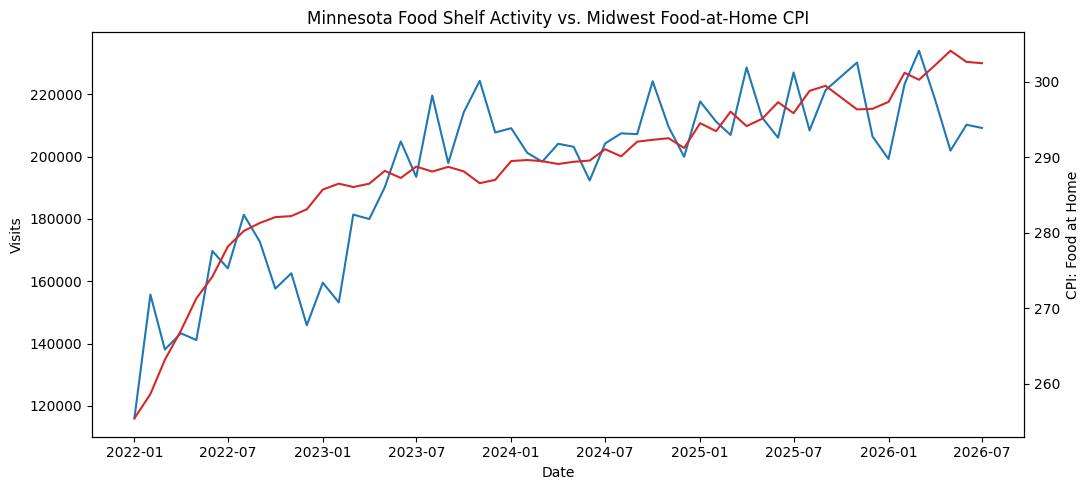

In [ ]:
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(
    statewide["date"],
    statewide["visits"],
    color="tab:blue",
    label="Visits (HouseholdsReg)"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Visits")

ax2 = ax1.twinx()

ax2.plot(
    statewide["date"],
    statewide["cpi"],
    color="tab:red",
    label="CPI: Food at Home (Midwest)"
)

ax2.set_ylabel(
    "CPI: Food at Home"
)

plt.title(
    "Minnesota Food Shelf Activity vs. Midwest Food-at-Home CPI"
)

fig.tight_layout()
plt.show()

### Raw level correlation

In [ ]:
print(
    "Raw level correlations:"
)

for metric in [
    "visits",
    "individuals",
    "pounds"
]:
    corr = statewide[metric].corr(
        statewide["cpi"]
    )

    print(
        f"{metric}: {corr:.3f}"
    )

Raw level correlations:
visits: 0.831
individuals: 0.839
pounds: 0.696


### Month-to-month changes

In [ ]:
# Calculate monthly percentage changes.

for col in [
    "visits",
    "individuals",
    "pounds",
    "cpi"
]:
    statewide[
        f"{col}_pct_change"
    ] = (
        statewide[col]
        .pct_change()
        * 100
    )

change_cols = [
    "date",
    "visits_pct_change",
    "individuals_pct_change",
    "pounds_pct_change",
    "cpi_pct_change"
]

print(
    statewide[change_cols].head(10)
)

        date  visits_pct_change  individuals_pct_change  pounds_pct_change  \
0 2022-01-01                NaN                     NaN                NaN   
1 2022-02-01          34.210640               -3.325362         -12.420995   
2 2022-03-01         -11.312880               24.720392          22.029939   
3 2022-04-01           3.767123                9.263960           3.908068   
4 2022-05-01          -1.511314                0.334157           1.920912   
5 2022-06-01          20.236198                5.920803           3.303111   
6 2022-07-01          -3.280756               -3.961041          -5.755598   
7 2022-08-01          10.458790               10.420873          12.744543   
8 2022-09-01          -4.746383               -3.792102          -6.462558   
9 2022-10-01          -8.732507               -2.019153           6.631322   

   cpi_pct_change  
0             NaN  
1        1.260078  
2        1.757934  
3        1.465352  
4        1.601867  
5        1.062010  
6

### Same-month relationship

In [ ]:
print(
    "Same-month correlations:"
)

for metric in [
    "visits",
    "individuals",
    "pounds"
]:
    corr = statewide[
        f"{metric}_pct_change"
    ].corr(
        statewide["cpi_pct_change"]
    )

    print(
        f"{metric}: {corr:.3f}"
    )

Same-month correlations:
visits: -0.005
individuals: 0.060
pounds: -0.096


### Lag analysis

In [ ]:
lag_results = []

for metric in [
    "visits",
    "individuals",
    "pounds"
]:

    for lag in range(0, 4):

        corr = statewide[
            f"{metric}_pct_change"
        ].corr(
            statewide["cpi_pct_change"].shift(lag)
        )

        lag_results.append({
            "metric": metric,
            "CPI_lag_months": lag,
            "correlation": corr
        })

lag_results = pd.DataFrame(
    lag_results
)

print(
    lag_results.round(3)
)

         metric  CPI_lag_months  correlation
0        visits               0       -0.005
1        visits               1        0.353
2        visits               2       -0.049
3        visits               3        0.022
4   individuals               0        0.060
5   individuals               1        0.399
6   individuals               2        0.013
7   individuals               3       -0.108
8        pounds               0       -0.096
9        pounds               1        0.253
10       pounds               2        0.078
11       pounds               3        0.035


In [ ]:
lag_table = lag_results.pivot(
    index="metric",
    columns="CPI_lag_months",
    values="correlation"
)

print(
    lag_table.round(3)
)

CPI_lag_months      0      1      2      3
metric                                    
individuals     0.060  0.399  0.013 -0.108
pounds         -0.096  0.253  0.078  0.035
visits         -0.005  0.353 -0.049  0.022


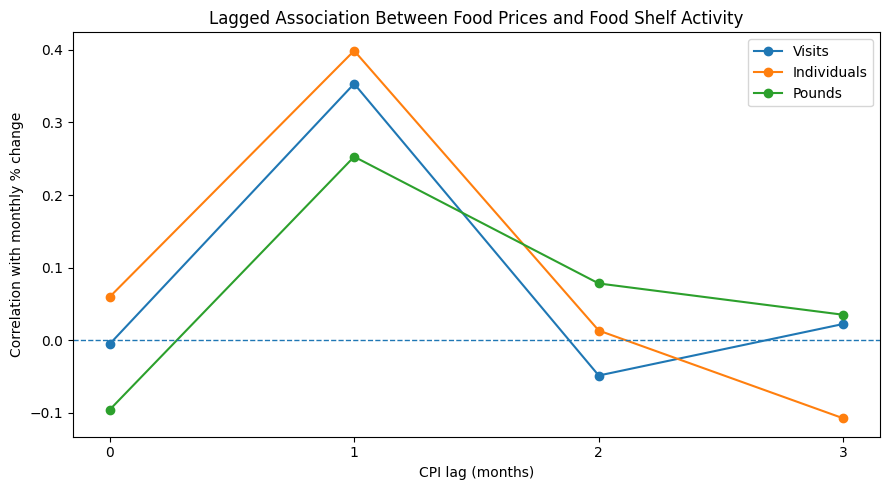

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

for metric in [
    "visits",
    "individuals",
    "pounds"
]:

    subset = lag_results[
        lag_results["metric"] == metric
    ]

    ax.plot(
        subset["CPI_lag_months"],
        subset["correlation"],
        marker="o",
        label=metric.capitalize()
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "CPI lag (months)"
)

ax.set_ylabel(
    "Correlation with monthly % change"
)

ax.set_title(
    "Lagged Association Between Food Prices and Food Shelf Activity"
)

ax.set_xticks(
    [0, 1, 2, 3]
)

ax.legend()

plt.tight_layout()
plt.show()

### Identify the strongest lag for each metric

In [ ]:
best_lags = (
    lag_results
    .sort_values(
        ["metric", "correlation"],
        ascending=[True, False]
    )
    .groupby("metric")
    .head(1)
    .sort_values("metric")
)

print(
    best_lags.round(3)
)

        metric  CPI_lag_months  correlation
5  individuals               1        0.399
9       pounds               1        0.253
1       visits               1        0.353


### Seasonality: month-of-year patterns

In [ ]:
statewide["month"] = (
    statewide["date"].dt.month
)

seasonality = (
    statewide
    .groupby("month")
    .agg(
        visits=("visits", "mean"),
        individuals=("individuals", "mean"),
        pounds=("pounds", "mean"),
        cpi=("cpi", "mean")
    )
)

print(
    seasonality.round(1)
)

         visits  individuals      pounds    cpi
month                                          
1      180310.8     551564.0  10498498.2  284.5
2      188907.2     547317.2   9967242.9  285.9
3      191744.0     588377.2  10733079.6  287.0
4      194862.2     603815.8  10798389.0  287.8
5      189765.6     584246.4  10724617.8  289.6
6      196630.4     593661.8  10781164.7  290.2
7      199596.8     601753.2  11009232.9  291.3
8      204173.5     613731.8  11619375.0  289.3
9      199774.2     601511.0  10788204.3  290.4
10     198651.3     616212.7  11711881.2  287.5
11     206623.8     651303.8  11915488.1  289.4
12     189989.8     583365.5  11266187.1  289.4


### Plot seasonal food shelf activity

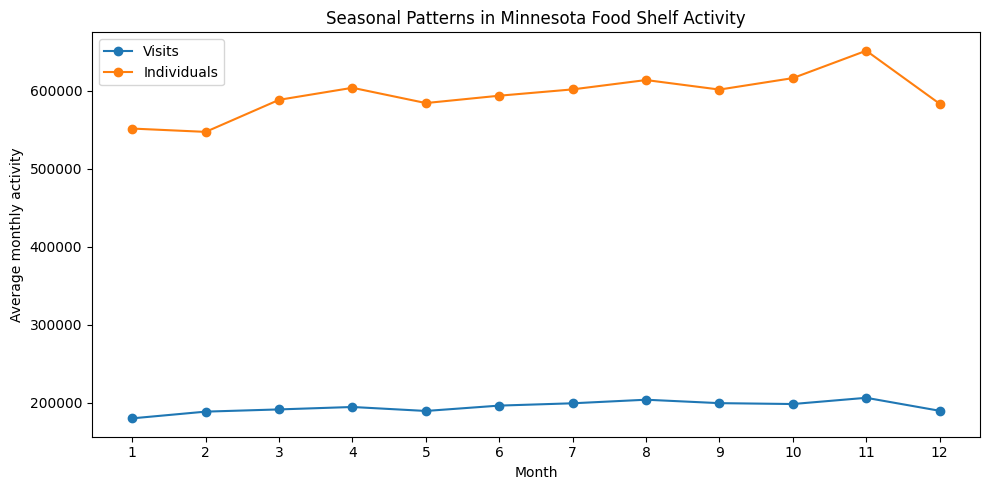

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    seasonality.index,
    seasonality["visits"],
    marker="o",
    label="Visits"
)

ax.plot(
    seasonality.index,
    seasonality["individuals"],
    marker="o",
    label="Individuals"
)

ax.set_xlabel("Month")
ax.set_ylabel(
    "Average monthly activity"
)

ax.set_title(
    "Seasonal Patterns in Minnesota Food Shelf Activity"
)

ax.set_xticks(
    range(1, 13)
)

ax.legend()

plt.tight_layout()
plt.show()

### Pounds separately

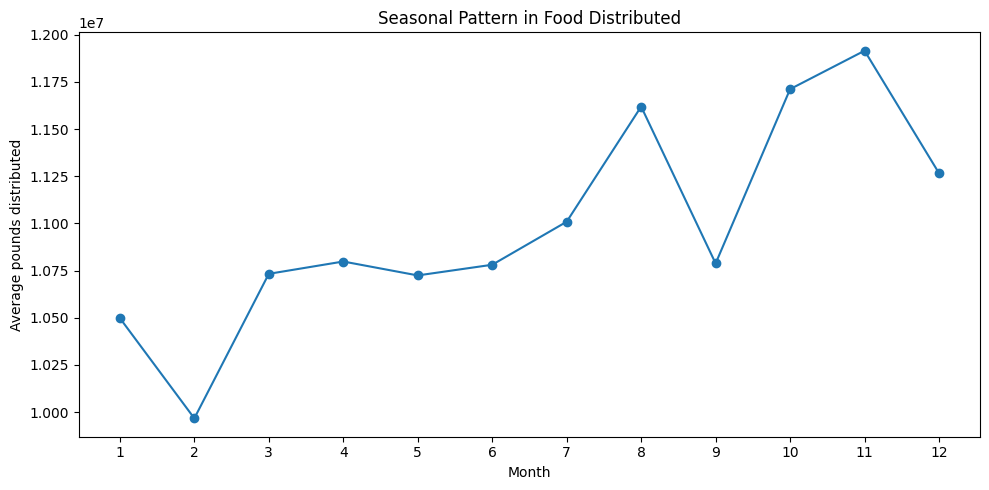

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    seasonality.index,
    seasonality["pounds"],
    marker="o"
)

ax.set_xlabel("Month")
ax.set_ylabel("Average pounds distributed")

ax.set_title(
    "Seasonal Pattern in Food Distributed"
)

ax.set_xticks(
    range(1, 13)
)

plt.tight_layout()
plt.show()

### Control for seasonality with month fixed effects

In [ ]:
reg_data = statewide.dropna(
    subset=[
        "cpi_pct_change",
        "visits_pct_change",
        "individuals_pct_change",
        "pounds_pct_change"
    ]
).copy()

reg_data["month"] = (
    reg_data["date"].dt.month
)

# visits
model_visits = smf.ols(
    "visits_pct_change ~ cpi_pct_change + C(month)",
    data=reg_data
).fit()

print(
    model_visits.summary()
)

# individuals
model_individuals = smf.ols(
    "individuals_pct_change ~ cpi_pct_change + C(month)",
    data=reg_data
).fit()

print(
    model_individuals.summary()
)

# pounds
model_pounds = smf.ols(
    "pounds_pct_change ~ cpi_pct_change + C(month)",
    data=reg_data
).fit()

print(
    model_pounds.summary()
)

                            OLS Regression Results                            
Dep. Variable:      visits_pct_change   R-squared:                       0.191
Model:                            OLS   Adj. R-squared:                 -0.052
Method:                 Least Squares   F-statistic:                    0.7855
Date:                Tue, 29 Sep 2026   Prob (F-statistic):              0.662
Time:                        15:22:13   Log-Likelihood:                -184.48
No. Observations:                  53   AIC:                             395.0
Df Residuals:                      40   BIC:                             420.6
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          4.5316      4.872      0.

### Better: lagged regression

In [ ]:
reg_data["cpi_change_lag1"] = (
    reg_data["cpi_pct_change"].shift(1)
)

reg_data_lag1 = reg_data.dropna(
    subset=["cpi_change_lag1"]
).copy()

# visits
model_visits_lag1 = smf.ols(
    "visits_pct_change ~ cpi_change_lag1 + C(month)",
    data=reg_data_lag1
).fit()

print(
    model_visits_lag1.summary()
)

# individuals
model_individuals_lag1 = smf.ols(
    "individuals_pct_change ~ cpi_change_lag1 + C(month)",
    data=reg_data_lag1
).fit()

print(
    model_individuals_lag1.summary()
)

# pounds
model_pounds_lag1 = smf.ols(
    "pounds_pct_change ~ cpi_change_lag1 + C(month)",
    data=reg_data_lag1
).fit()

print(
    model_pounds_lag1.summary()
)

                            OLS Regression Results                            
Dep. Variable:      visits_pct_change   R-squared:                       0.265
Model:                            OLS   Adj. R-squared:                  0.039
Method:                 Least Squares   F-statistic:                     1.170
Date:                Tue, 29 Sep 2026   Prob (F-statistic):              0.337
Time:                        15:22:17   Log-Likelihood:                -170.82
No. Observations:                  52   AIC:                             367.6
Df Residuals:                      39   BIC:                             393.0
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           3.7980      3.731     

### Compact regression summary - for slides

In [ ]:
reg_summary = pd.DataFrame({
    "Metric": [
        "Visits",
        "Individuals",
        "Pounds"
    ],
    "Same-month coefficient": [
        model_visits.params.get(
            "cpi_pct_change", np.nan
        ),
        model_individuals.params.get(
            "cpi_pct_change", np.nan
        ),
        model_pounds.params.get(
            "cpi_pct_change", np.nan
        )
    ],
    "1-month-lag coefficient": [
        model_visits_lag1.params.get(
            "cpi_change_lag1", np.nan
        ),
        model_individuals_lag1.params.get(
            "cpi_change_lag1", np.nan
        ),
        model_pounds_lag1.params.get(
            "cpi_change_lag1", np.nan
        )
    ]
})

print(
    reg_summary.round(4)
)

        Metric  Same-month coefficient  1-month-lag coefficient
0       Visits                 -0.8442                   3.4949
1  Individuals                  0.8350                   4.2359
2       Pounds                 -0.4449                   2.4304


### Final analytical summary table

In [ ]:
summary_table = []

for metric in [
    "visits",
    "individuals",
    "pounds"
]:

    metric_lags = lag_results[
        lag_results["metric"] == metric
    ].copy()

    best_row = metric_lags.loc[
        metric_lags["correlation"].idxmax()
    ]

    same_month = metric_lags.loc[
        metric_lags["CPI_lag_months"] == 0,
        "correlation"
    ].iloc[0]

    summary_table.append({
        "Metric": metric,
        "Same_month_corr": same_month,
        "Strongest_lag_months": int(
            best_row["CPI_lag_months"]
        ),
        "Strongest_lag_corr": best_row[
            "correlation"
        ]
    })

summary_table = pd.DataFrame(
    summary_table
)

print(
    summary_table.round(3)
)

        Metric  Same_month_corr  Strongest_lag_months  Strongest_lag_corr
0       visits           -0.005                     1               0.353
1  individuals            0.060                     1               0.399
2       pounds           -0.096                     1               0.253


###